# Using Google Colab

Read through the **Getting started** paragraph in the [official documentation](https://colab.research.google.com/). You may also want to take a look into the **More resources** section.

To add a new code block or text block, use the buttons in the menus above or hover your mouse between two blocks, where more buttons should appear.

To execute all code blocks within this document, select `Runtime -> Run all`. When you submit your solution, this should run without throwing an error.

Sometimes, previously defined variables cause trouble in later executions. If this is the case, you can select `Runtime -> Restart runtime` to restart the runtime and erase all previous definitions.

# Guidelines for Solving the Assignments

In these assignments, you are expected to implement the algorithms yourself rather than relying on Python’s built-in functions that already solve essential parts of the task, such as `index`, `min`, `max`, or `sort`. However, it is of course fine to use general-purpose functions like `len` or `range`.

You may discuss the assignments in general terms with other groups to clarify ideas, but every group must produce their own solutions independently. Copying solutions (or parts thereof) from other groups or from external sources is strictly prohibited—this includes material generated by AI text generators such as ChatGPT or similar tools.

# Work Distribution

***
Huanyu: I filled the functions for Question 6 and wrote some code for estimate the value of coefficients.

Hannes: I wrote the code for selection sort, sinksort and a version for insertion sort

Joel: I wrote the different version of insertion sort, and answered the first runtime comparison

Nora: I wrote the modified sink sort and accompanying description.
***

# Initialisation

This section contains code that is later used to test, measure and plot your implementations. You need to run it once to initialise it.

⇩ Click here to initialise the code.

In [ ]:
# tests

import random

def shuffle(list):
  random.shuffle(list)
  return list

tests = [(name, unsorted, sorted(unsorted)) for (name, unsorted) in [
    ("empty list", []),
    ("one element", [42]),
    ("digits ascending", list(range(10))),
    ("digits descending", list(reversed(range(10)))),
    ("digits shuffled", shuffle(list(range(10)))),
    ("all entries the same", [42 for _ in range(10)]),
    ("some duplicates", shuffle(list(range(10)) + list(range(5)))),
    ("negative numbers", shuffle([x - 10 for x in list(range(20))])),
    ("float numbers", shuffle([x * 3.14 for x in list(range(20))])),
    ("mixed numbers", shuffle([x * 3.14 for x in list(range(10))] + list(range(10)))),
    *[("random numbers " + str(idx) + " (small)", [random.randrange(1000) for _ in range(20)]) for idx in range(0, 5)],
    *[("random numbers " + str(idx) + " (medium)", [random.randrange(10000) for _ in range(200)]) for idx in range(5, 10)],
    *[("random numbers " + str(idx) + " (large)", [random.randrange(100000) for _ in range(2000)]) for idx in range(10, 15)],
]]

def run_tests(fun):
  print("executing all tests on %s..." % (fun.__name__))
  ok = 0
  err = 0
  for name, input, expected in tests:
    copy = input.copy()
    try:
      fun(copy)
    except Exception as e:
      print("Test '%s' raised an exception!\n  input:     %s\n  expected:  %s\n  exception: %s" % (name, input, expected, e))
      raise e
    else:
      if copy == expected:
        print("Test '%s' passed!" % (name))
        ok += 1
      else:
        print("Test '%s' failed!\n  input:     %s\n  output:    %s\n  expected:  %s" % (name, input, copy, expected))
        err +=1
  print("%s (summary): %d/%d OK, %d/%d ERROR" % (fun.__name__, ok, len(tests), err, len(tests)))

# runtime parameters
num_samples = 20
sizes = [200 * i for i in range(1, 10)]

# runtime measurement
import time
runtimeDict = {}
def measure_runtime(funs):
  inputs = [[[random.random() for _ in range(size)] for _ in range(num_samples)] for size in sizes]

  for fun in funs:
    runtimes = []
    for batch in inputs:
      batch_rt = []
      for input in batch:
        copy = input.copy()
        start_time = time.time()
        fun(copy)
        end_time = time.time()
        batch_rt.append(end_time - start_time)
      runtimes.append(min(batch_rt))
    runtimeDict[fun.__name__] = runtimes

# runtime plot
import matplotlib.pyplot as plt
def plot_runtime(funs, funs_checkered=None):
  for fun in funs:
    plt.plot(sizes, runtimeDict[fun.__name__], label=fun.__name__)
  if funs_checkered:
    plt.gca().set_prop_cycle(None)
    for fun in funs_checkered:
      plt.plot(sizes, runtimeDict[fun.__name__], '--', label=fun.__name__)

  plt.xlabel('List Length')
  plt.ylabel('Runtime (seconds)')
  plt.title('Runtime vs List Length')

  plt.legend()
  plt.show()

# Sorting Algorithms

In this exercise, you are going to implement the *Insertion Sort*, *Selection Sort* and *Sink Sort* algorithms.

- Each of your sorting functions should accept an unsorted list of numbers and sort it (in place). Of course, you are allowed to add as many helper functions as needed.
- Note that arrays (or lists) in the textbook are indexed from 1, whereas in Python (and most other programming languages) they are indexed from 0.
- Your implementation should have a good performance with respect to the asymptotic complexity found in the literature.

At the bottom of each code block, there is a function call to test your algorithm implementation. Run it to check if your implementation is correct.

Below the algorithms in this document, there is a code block that reports runtime statistics. Furthermore, at the end of the document, there are a couple of questions you should answer.

### 1. Insertion Sort (2 points)

Implement Insertion Sort as seen in the lecture.

In [ ]:
def insertionsort(A):
    for i in range(1, len(A)):
        key = A[i]
        j = i - 1
        while j >= 0 and A[j] > key:
            A[j + 1] = A[j]
            j -= 1
        A[j + 1] = key
    return A

print(insertionsort([8, 4, 5, 1, 6, 7, 2, 3]))


run_tests(insertionsort)


[1, 2, 3, 4, 5, 6, 7, 8]
executing all tests on insertionsort...
Test 'empty list' passed!
Test 'one element' passed!
Test 'digits ascending' passed!
Test 'digits descending' passed!
Test 'digits shuffled' passed!
Test 'all entries the same' passed!
Test 'some duplicates' passed!
Test 'negative numbers' passed!
Test 'float numbers' passed!
Test 'mixed numbers' passed!
Test 'random numbers 0 (small)' passed!
Test 'random numbers 1 (small)' passed!
Test 'random numbers 2 (small)' passed!
Test 'random numbers 3 (small)' passed!
Test 'random numbers 4 (small)' passed!
Test 'random numbers 5 (medium)' passed!
Test 'random numbers 6 (medium)' passed!
Test 'random numbers 7 (medium)' passed!
Test 'random numbers 8 (medium)' passed!
Test 'random numbers 9 (medium)' passed!
Test 'random numbers 10 (large)' passed!
Test 'random numbers 11 (large)' passed!
Test 'random numbers 12 (large)' passed!
Test 'random numbers 13 (large)' passed!
Test 'random numbers 14 (large)' passed!
insertionsort (summ

In [ ]:
# Another way (similar to the book version to implement it)
"""
def insertionsort(A):
  i = 1 # this is what we move
  while i < len(A):
    j = i # this is what will let us see each item to compare
    while j > 0 and A[j-1] > A[j]:
      A[j], A[j-1] =  A[j-1], A[j]
      j -= 1
    i += 1
  return A

print(insertionsort([8, 4, 5, 1, 6, 7, 2, 3]))
run_tests(insertionsort)
"""

'\ndef insertionsort(A):\n  i = 1 #\xa0this is what we move\n  while i < len(A):\n    j = i #\xa0this is what will let us see each item to compare\n    while j > 0 and A[j-1] > A[j]:\n      A[j], A[j-1] =  A[j-1], A[j]\n      j -= 1\n    i += 1\n  return A\n\nprint(insertionsort([8, 4, 5, 1, 6, 7, 2, 3]))\nrun_tests(insertionsort)\n'

### 2. Selection Sort (2 points)

Implement Selection Sort, which is a sorting algorithm that proceeds as follows:
- Throughout the execution, the array is divided into a sorted lower part and an unsorted upper
part.
- Initially, the sorted lower part is empty. Upon termination, the sorted lower part spans the
whole array.
- In each iteration of the algorithm:
 1. The algorithm searches for the minimal element of the unsorted upper part.
 2. This minimal element is swapped with the first element of the unsorted upper part of
the array.
 3. The boundary between the sorted lower part and the unsorted upper part is raised by
one to include the newly sorted element.

In [ ]:
def selectionsort(A):
    n = len(A)
    for i in range(n - 1):
        min_idx = i
        for j in range(i + 1, n):
            if A[j] < A[min_idx]:
                min_idx = j
        A[i], A[min_idx] = A[min_idx], A[i]

    return A

print(selectionsort([8,4,1,7,2,3,6,5]))

run_tests(selectionsort)

[1, 2, 3, 4, 5, 6, 7, 8]
executing all tests on selectionsort...
Test 'empty list' passed!
Test 'one element' passed!
Test 'digits ascending' passed!
Test 'digits descending' passed!
Test 'digits shuffled' passed!
Test 'all entries the same' passed!
Test 'some duplicates' passed!
Test 'negative numbers' passed!
Test 'float numbers' passed!
Test 'mixed numbers' passed!
Test 'random numbers 0 (small)' passed!
Test 'random numbers 1 (small)' passed!
Test 'random numbers 2 (small)' passed!
Test 'random numbers 3 (small)' passed!
Test 'random numbers 4 (small)' passed!
Test 'random numbers 5 (medium)' passed!
Test 'random numbers 6 (medium)' passed!
Test 'random numbers 7 (medium)' passed!
Test 'random numbers 8 (medium)' passed!
Test 'random numbers 9 (medium)' passed!
Test 'random numbers 10 (large)' passed!
Test 'random numbers 11 (large)' passed!
Test 'random numbers 12 (large)' passed!
Test 'random numbers 13 (large)' passed!
Test 'random numbers 14 (large)' passed!
selectionsort (summ

### 3. Sink Sort (2 points)

Implement Sink Sort, which is a sorting algorithm that proceeds as follows:
- Compare the first and second element of the array. If they are mismatched (the second element is smaller than the first one), swap them.
- Compare the second and third element of the array and swap them if they are mismatched.
- Continue until the end of the array, i.e. the second to last element and the last element.
- If you have swapped at least one pair of elements, repeat from the beginning.

In [ ]:
def sinksort(A):
  swaps = 1
  n = len(A)
  while swaps > 0:
    swaps = 0 #it won't check this until the end of the while loop, so if no swaps were made then it is sorted and returned!

    for i in range(n-1): #loop over the unsorted elements
      if A[i] > A[i+1]:
        A[i], A[i+1] = A[i+1], A[i] #swapsies
        swaps += 1
  return A

run_tests(sinksort)

executing all tests on sinksort...
Test 'empty list' passed!
Test 'one element' passed!
Test 'digits ascending' passed!
Test 'digits descending' passed!
Test 'digits shuffled' passed!
Test 'all entries the same' passed!
Test 'some duplicates' passed!
Test 'negative numbers' passed!
Test 'float numbers' passed!
Test 'mixed numbers' passed!
Test 'random numbers 0 (small)' passed!
Test 'random numbers 1 (small)' passed!
Test 'random numbers 2 (small)' passed!
Test 'random numbers 3 (small)' passed!
Test 'random numbers 4 (small)' passed!
Test 'random numbers 5 (medium)' passed!
Test 'random numbers 6 (medium)' passed!
Test 'random numbers 7 (medium)' passed!
Test 'random numbers 8 (medium)' passed!
Test 'random numbers 9 (medium)' passed!
Test 'random numbers 10 (large)' passed!
Test 'random numbers 11 (large)' passed!
Test 'random numbers 12 (large)' passed!
Test 'random numbers 13 (large)' passed!
Test 'random numbers 14 (large)' passed!
sinksort (summary): 25/25 OK, 0/25 ERROR


### 4. Runtime Comparisons (2 points)

The following code will measure the runtime of your algorithm implementations.

Compare the reported runtimes. What do you observe? How do you explain your observations?

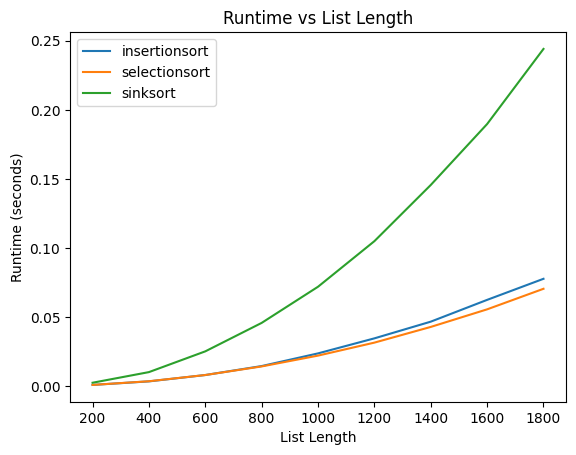

In [ ]:
measure_runtime([insertionsort, selectionsort, sinksort])
plot_runtime([insertionsort, selectionsort, sinksort])

**Answer:**

***They all follow the same \(n^2\) pattern. This makes sense as for the implementations, each algorithm can go through the list many times, as we can see:***

***For selectionsort, there is a loop inside another loop, so for every item it checks many of the remaining items. Insertionsort also has a loop with a while inside it, and in the worst case it may move through all the whole sorted part of the list each time. Sinksort keeps doing full passes through the list until no swaps are made, so it can also need around \(n\) passes of \(n\) comparisons.***
***
This is why when the list gets bigger, the runtime grows in bigger steps than linearly and follows approximately an \(n^2\) curve. This would become even more visible with larger lists.
***

### 5. Modified Sink Sort (1 point)

Have another look at the description of Sink Sort. Is it really necessary to go through the whole array in each iteration? Suggest an optimisation, implement it and compare the runtime to the unmodified version.



In [ ]:
def mod_sinksort(A):
  swaps = 1
  n = len(A)
  while swaps > 0:
    swaps = 0 #The while loop won't check this variable until the end of the while loop, so if no swaps were made then it is sorted and returned!

    for i in range(n-1): #loop over the unsorted elements(not including the last one)
      if A[i] > A[i+1]:
        A[i], A[i+1] = A[i+1], A[i] #swapsies
        swaps += 1 #if we swap, then we indicate it using this variable.
    n -= 1 #optimisation:)
  return A



run_tests(mod_sinksort)

executing all tests on mod_sinksort...
Test 'empty list' passed!
Test 'one element' passed!
Test 'digits ascending' passed!
Test 'digits descending' passed!
Test 'digits shuffled' passed!
Test 'all entries the same' passed!
Test 'some duplicates' passed!
Test 'negative numbers' passed!
Test 'float numbers' passed!
Test 'mixed numbers' passed!
Test 'random numbers 0 (small)' passed!
Test 'random numbers 1 (small)' passed!
Test 'random numbers 2 (small)' passed!
Test 'random numbers 3 (small)' passed!
Test 'random numbers 4 (small)' passed!
Test 'random numbers 5 (medium)' passed!
Test 'random numbers 6 (medium)' passed!
Test 'random numbers 7 (medium)' passed!
Test 'random numbers 8 (medium)' passed!
Test 'random numbers 9 (medium)' passed!
Test 'random numbers 10 (large)' passed!
Test 'random numbers 11 (large)' passed!
Test 'random numbers 12 (large)' passed!
Test 'random numbers 13 (large)' passed!
Test 'random numbers 14 (large)' passed!
mod_sinksort (summary): 25/25 OK, 0/25 ERROR


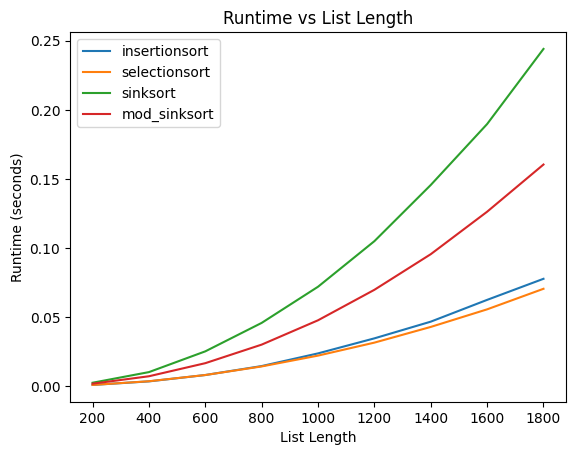

In [ ]:
measure_runtime([mod_sinksort])
plot_runtime([insertionsort, selectionsort, sinksort, mod_sinksort])

**Answer:**

***If the array is sorted in descending index order, and the elements are sorted from lower to higher values, then by the end of the first for loop the largest element will always be at the end of the array, and therefore sorted. This means we do not need to check it again in the next loop, and thus the next loop becomes n-1, and the next n-2. This reduces the amount of comparisons and assignments needed, and thus the overall runtime.***

### 6. Runtime Approximations (1 point - hard question)

Using the statistics from the tests, for each algorithm, find a function `f(n)` which *approximately* describes the runtime of the algorithm in *seconds*, depending on the input size `n`. For example, if Insertion Sort takes 5 milliseconds to sort a list of 1000 numbers and 20 milliseconds to sort a list of 2000 numbers, then it should be that `f_insertion(1000)≈0.005` and `f_insertion(2000)≈0.020`.

It is possible to solve this by trial-and-error, but how would you get the answer by a simple calculation?

In [ ]:
# coefficient for insertion sort
times = runtimeDict["insertionsort"]
coefficients = []
for n, t in zip(sizes, times):
    coefficient = t / (n**2)
    coefficients.append(coefficient)
    print(n, coefficient)

insertion_average = sum(coefficients[1:]) / len(coefficients[1:]) # avoid the noise from first n=200
print("insertion_sort_average:", insertion_average)

# coefficient for selection sort
times = runtimeDict["selectionsort"]
coefficients = []
for n, t in zip(sizes, times):
    coefficient = t / (n**2)
    coefficients.append(coefficient)
    print(n, coefficient)

select_average = sum(coefficients[1:]) / len(coefficients[1:]) # avoid the noise from first n=200
print("selection_sort_average:", select_average)

# coefficient for sink sort
times = runtimeDict["sinksort"]
coefficients = []
for n, t in zip(sizes, times):
    coefficient = t / (n**2)
    coefficients.append(coefficient)
    print(n, coefficient)

sink_average = sum(coefficients[1:]) / len(coefficients[1:]) # avoid the noise from first n=200
print("sink_sort_average:", sink_average)

# coefficient for mod_sink sort
times = runtimeDict["mod_sinksort"]
coefficients = []
for n, t in zip(sizes, times):
    coefficient = t / (n**2)
    coefficients.append(coefficient)
    print(n, coefficient)

mod_sink_average = sum(coefficients[1:]) / len(coefficients[1:]) # avoid the noise from first n=200
print("mod_sink_sort_average:", mod_sink_average)

200 1.9514560699462892e-08
400 2.0913779735565185e-08
600 2.2081534067789714e-08
800 2.2556260228157043e-08
1000 2.3617029190063478e-08
1200 2.3956927988264297e-08
1400 2.377057562069017e-08
1600 2.4361349642276766e-08
1800 2.3956946384759598e-08
insertion_sort_average: 2.3151800357195783e-08
200 1.9556283950805664e-08
400 2.147108316421509e-08
600 2.2078222698635527e-08
800 2.2143125534057617e-08
1000 2.200770378112793e-08
1200 2.181182305018107e-08
1400 2.182417986344318e-08
1600 2.1683238446712493e-08
1800 2.1725009988855433e-08
selection_sort_average: 2.1843048315903543e-08
200 5.906224250793457e-08
400 6.287842988967895e-08
600 6.969703568352593e-08
800 7.139928638935089e-08
1000 7.187652587890625e-08
1200 7.283058431413438e-08
1400 7.426203513632015e-08
1600 7.409481331706047e-08
1800 7.533298598395454e-08
sink_sort_average: 7.154646207411645e-08
200 4.1812658309936524e-08
400 4.410594701766968e-08
600 4.5911471048990885e-08
800 4.681609570980072e-08
1000 4.758620262145996e-08
12

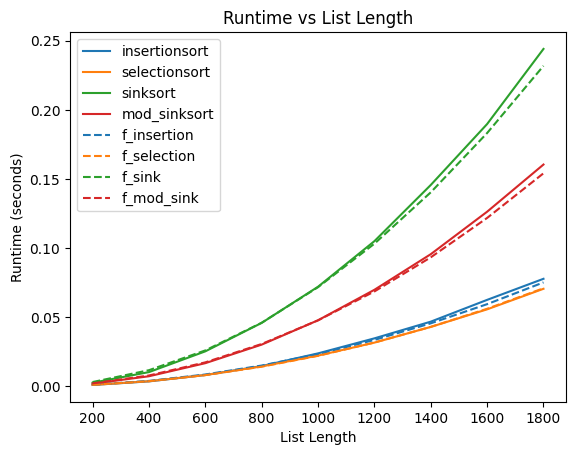

In [ ]:
def f_insertion(size):
  return insertion_average*size**2

def f_selection(size):
  return select_average*size**2
def f_sink(size):
  return sink_average*size**2

def f_mod_sink(size):
  return mod_sink_average*size**2

# plot all functions
for fun in [f_insertion, f_selection, f_sink, f_mod_sink]:
  runtimeDict[fun.__name__] = [fun(size) for size in sizes]
plot_runtime([insertionsort, selectionsort, sinksort, mod_sinksort], [f_insertion, f_selection, f_sink, f_mod_sink])

**Answer:**
Since the time complexity of all four sorting algorithms are quadratic, so the function $f(n)=an^2$ can be used to approximately represent the relation between the size $n$ and the time $t$. So for each data point, we can calculate $a = \frac{t}{n^2}$, where $t$ denotes the runtime and $n$ denotes the input size. And since the runtime of the  first datapoint $(n=200)$ is very short, we exclude it as a noise. Then we use the average of the remaining coefficients as $a$. As shown in the plot, the resulting functions approximately fit the measured runtime curves.